In [1]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np

Note: you may need to restart the kernel to use updated packages.


# Windowed Oscillator Tracking

## Three models, one idea — track a sinusoid as a phasor `ψ = Re + i·Im`

Everything in this family estimates the slowly-varying complex amplitude (phasor) of one
or more lines. They differ only in **which frame** the phasor lives in and **how the signal
is fed** to the filter:

| model | input | demodulate? | frame | `F` | `H` | best for |
|---|---|---|---|---|---|---|
| `AnalyticOscillatorModel` | analytic `[re, im]` | yes (rotate signal) | rotating | `expm(Δω)` | identity | the **atom** / teaching block |
| `OscillatorModel` *(this nb)* | **real** | yes — inside `preprocess` (Hilbert) | rotating | `expm(Δω)` | identity (on band) | **weak, narrowband** lines (violin modes) |
| `PhasorOscillatorModel` *(nb 03)* | **real** | **no** | lab | `I` | `H(t)=[cos ωt, −sin ωt]` | **strong, wide-spread** lines (mains) |

The split that matters is **rotating frame vs lab frame** — i.e. *do you demodulate the
signal (rotating) or keep it real and put the carrier in a time-varying `H(t)` (lab)?* Both
are fed a **real** signal. `AnalyticOscillatorModel` is the rotating-frame **atom** that
`OscillatorModel` stacks; `PhasorOscillatorModel` (notebook 03, with its mains
specialization `PowerGridStateModel`) is the lab-frame sibling. Setting `wc=0` does **not**
turn one into the other — it only stops the rotation; the observation map (2 complex
channels vs 1 real channel) still differs.

## This notebook — the rotating-frame `OscillatorModel`

`OscillatorModel` is **one analysis window** `[fc ± dfc]` over a **real** signal. Given a
candidate frequency list it **masks** down to the modes inside the band and tracks them
jointly as complex envelopes — **FUSED**, one demodulated channel `z = Σ ψ_i`
(`H = [I₂ … I₂]`). Real signal in, real band reconstruction out.

Several windows compose **INDEPENDENT** into an `OscillatorCompositeModel`
(or an `InharmonicOscillatorModel` / `HarmonicOscillatorModel` ladder), each demodulating
the *same* signal at its own carrier `fc`; the cleaned signal is `strain − Σ windows`.

We walk the four configurations — **single peak**, **multiple peaks in one window**,
**inharmonic mask**, **multiwindow bank** — then the standalone `AnalyticOscillatorModel`
(a single rotating-frame mode).

## Case 1 — single peak

One frequency inside the window → a single mode `[Re, Im]`. The envelope `|ψ|` tracks the
(decaying) amplitude; `reconstruct` returns the real waveform.

n, m = 2 2 | kept frequencies: [180.1] Hz


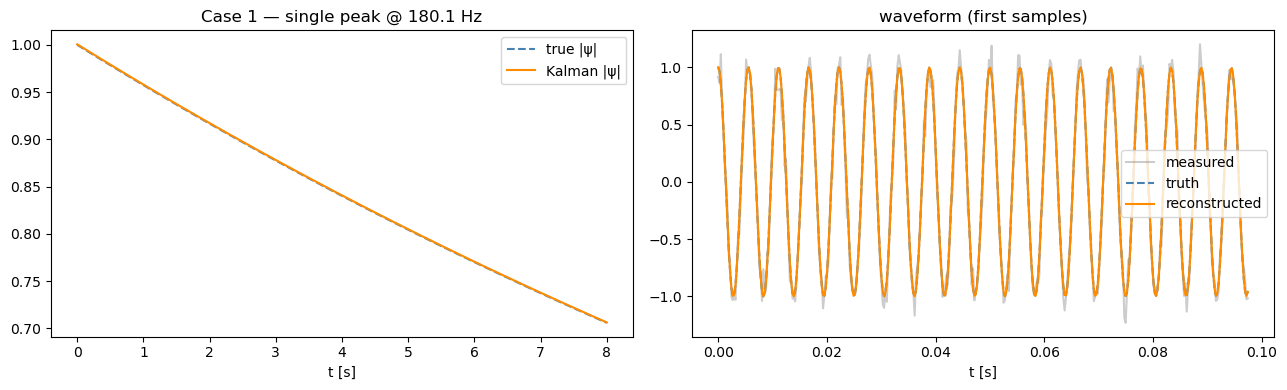

In [2]:
from kalman.apps.oscillators import OscillatorModel
import matplotlib.pyplot as plt

fs, T = 4096.0, 8.0
N = int(T*fs); t = np.arange(N)/fs
f1, A1, Q1 = 180.1, 1.0, 1.3e4
tau1 = Q1/(np.pi*f1)
clean  = A1*np.exp(-t/tau1)*np.cos(2*np.pi*f1*t)
strain = clean + 0.1*np.random.randn(N)

m = OscillatorModel("mode", [f1], fc=f1, dfc=5.0, Q=Q1, fs=fs,
                    measurement_uncertainty=0.1, process_uncertainty=1e-4)
rec   = m.filter(strain, smooth=True)
amp   = m.amplitudes(rec)[:, 0]
recon = m.reconstruct(rec)
print("n, m =", m.n, m.m, "| kept frequencies:", np.round(m.frequencies, 2), "Hz")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(t, A1*np.exp(-t/tau1), "--", color="steelblue", label="true |\u03c8|")
ax[0].plot(t, amp, color="darkorange", label="Kalman |\u03c8|")
ax[0].set_title(f"Case 1 \u2014 single peak @ {f1} Hz"); ax[0].set_xlabel("t [s]"); ax[0].legend()
ns = 400
ax[1].plot(t[:ns], strain[:ns], color="gray", alpha=0.4, label="measured")
ax[1].plot(t[:ns], clean[:ns], "--", color="steelblue", label="truth")
ax[1].plot(t[:ns], recon[:ns], color="darkorange", label="reconstructed")
ax[1].set_title("waveform (first samples)"); ax[1].set_xlabel("t [s]"); ax[1].legend()
plt.tight_layout(); plt.show()

## Case 2 — multiple peaks in one window (FUSED joint)

Three closely-spaced lines fall inside a single 4 Hz window. They cannot be isolated
separately, so they share one demodulated channel and are estimated **jointly** (`m = 2`,
`n = 6`). This is the joint Kalman of Moisset et al. (2025) / Mukherjee & Finn (1999).

n, m = 6 2 (3 modes share ONE demodulated band channel)


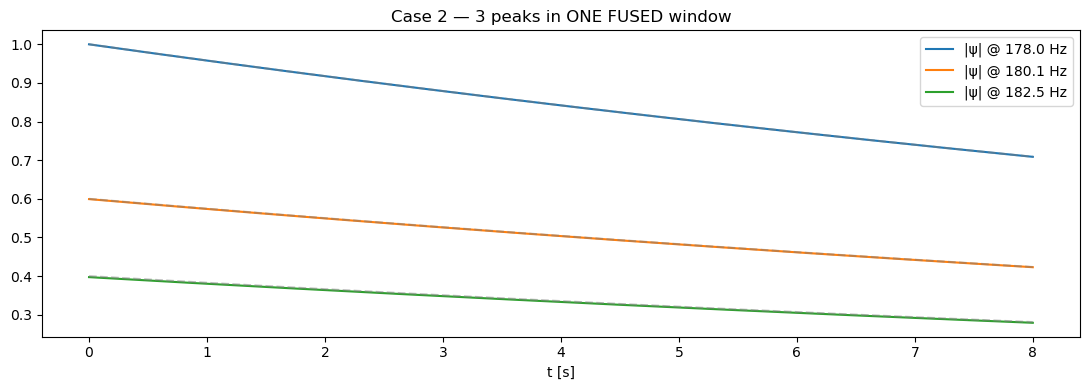

In [3]:
freqs = [178.0, 180.1, 182.5]; amps = [1.0, 0.6, 0.4]; Qs = [1.3e4]*3
clean = sum(A*np.exp(-t/(Q/(np.pi*f)))*np.cos(2*np.pi*f*t) for A,f,Q in zip(amps,freqs,Qs))
strain = clean + 0.1*np.random.randn(N)

m = OscillatorModel("cluster", freqs, fc=180.0, dfc=4.0, Q=Qs, fs=fs,
                    measurement_uncertainty=0.1, process_uncertainty=1e-4)
rec = m.filter(strain, smooth=True)
amp = m.amplitudes(rec)
print("n, m =", m.n, m.m, "(3 modes share ONE demodulated band channel)")

fig, ax = plt.subplots(figsize=(11, 4))
for k, f in enumerate(m.frequencies):
    ax.plot(t, amp[:, k], label=f"|\u03c8| @ {f:.1f} Hz")
    ax.plot(t, amps[k]*np.exp(-t/(Qs[k]/(np.pi*f))), "--", color="gray", alpha=0.5)
ax.set_title(f"Case 2 \u2014 {len(m.frequencies)} peaks in ONE FUSED window")
ax.set_xlabel("t [s]"); ax.legend(); plt.tight_layout(); plt.show()

## Case 3 — inharmonic mask

`InharmonicOscillatorModel` **is** one `OscillatorModel` window whose candidate list is a
ladder `f_n = n·f0·√(1+B·n²)`. A window centred on the fundamental keeps **only** the
in-band partial — the others are masked out.

In [4]:
from kalman.apps.oscillators import InharmonicOscillatorModel

m = InharmonicOscillatorModel("mask", f0=180.1, fc=189.32, dfc=5.0, n_harmonics=3, B=0.105, fs=4096.0)
print("inharmonic ladder:", np.round(m.partial_freqs, 2), "Hz")
print(f"window {m.fc:.1f} \u00b1 {m.dfc:.0f} Hz keeps:", np.round(m.frequencies, 2),
      "Hz  \u2014 2nd/3rd partials masked out")

inharmonic ladder: [189.32 429.23 753.52] Hz
window 189.3 ± 5 Hz keeps: [189.32] Hz  — 2nd/3rd partials masked out


## Case 4 — multiwindow bank (KAGRA violin-mode subtraction)

Put one window on each partial of the ladder and compose them **INDEPENDENT** in an
`OscillatorCompositeModel`. The single real strain is broadcast to every window; each
window subtracts its band, and the cleaned residual is `strain − Σ windows`.

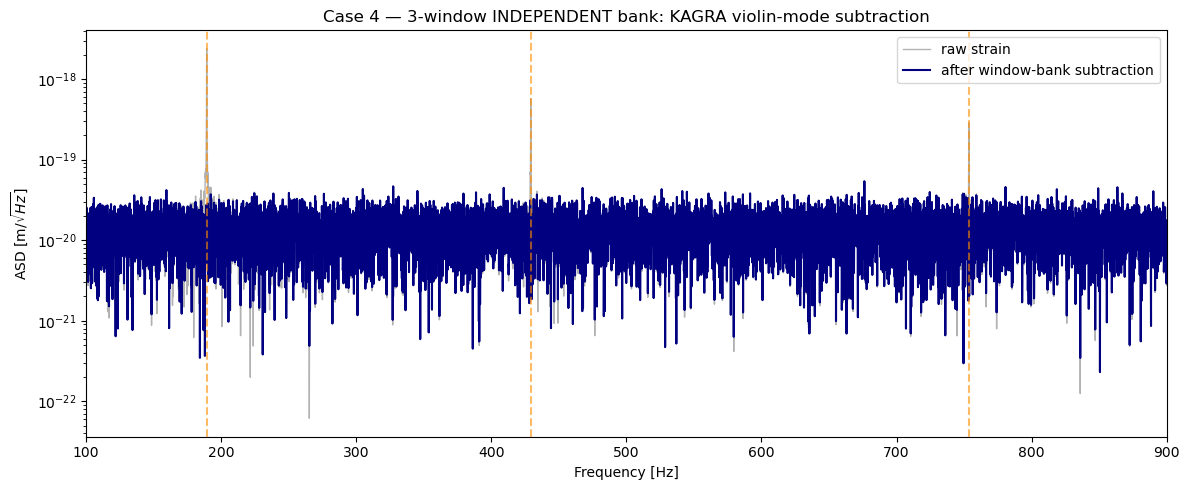

Peak suppression:
  mode 1 @ 189.3 Hz:  +36.1 dB
  mode 2 @ 429.2 Hz:  +24.8 dB
  mode 3 @ 753.5 Hz:  +18.5 dB


In [5]:
from kalman.apps.oscillators import OscillatorModel, OscillatorCompositeModel, partial_frequencies
from numpy.fft import rfft, rfftfreq

np.random.seed(0)
f0v, Bv, nv = 180.1, 0.105, 3
fsv, Tv = 4096.0, 10.0; Nv = int(Tv*fsv); tv = np.arange(Nv)/fsv
noise = 5e-19
Qs = [1.3e4, 1.8e4, 2.1e4]; A = [1.0e-18, 3.0e-19, 1.5e-19]
freqs = partial_frequencies(f0v, Bv, nv)
strain = noise*np.random.randn(Nv)
for a, f, Q in zip(A, freqs, Qs):
    strain += a*np.exp(-tv/(Q/(np.pi*f)))*np.cos(2*np.pi*f*tv)

# one window per partial, composed INDEPENDENT into a bank
windows = [OscillatorModel("KAGRA", freqs, fc=f, dfc=5.0, Q=Q, fs=fsv,
                           measurement_uncertainty=40*noise, process_uncertainty=1e-21)
           for f, Q in zip(freqs, Qs)]
bank = OscillatorCompositeModel(*windows)
for w, a in zip(bank.windows, A): w.initial_state([[a, 0.0]])
bank.initial_state(np.vstack([w.x0 for w in bank.windows]))
rec = bank.filter(strain, smooth=True)
final = bank.reconstruct(rec); cleaned = strain - final

fr = rfftfreq(Nv, 1/fsv); nrm = 2/np.sqrt(fsv*Nv)
Sr = np.abs(rfft(strain))*nrm; Sc = np.abs(rfft(cleaned))*nrm
fig, ax = plt.subplots(figsize=(12, 5))
ax.semilogy(fr, Sr, color="gray", alpha=0.6, lw=1.0, label="raw strain")
ax.semilogy(fr, Sc, color="navy", lw=1.5, label="after window-bank subtraction")
for fk in freqs: ax.axvline(fk, ls="--", color="darkorange", alpha=0.6)
ax.set_xlim(100, 900); ax.set_xlabel("Frequency [Hz]"); ax.set_ylabel(r"ASD [m/$\sqrt{Hz}$]")
ax.set_title(f"Case 4 \u2014 {len(bank.windows)}-window INDEPENDENT bank: KAGRA violin-mode subtraction")
ax.legend(); plt.tight_layout(); plt.show()
print("Peak suppression:")
for k, fk in enumerate(freqs):
    mm = (fr > fk-3) & (fr < fk+3)
    print("  mode %d @%6.1f Hz:  %+.1f dB" % (k+1, fk, 20*np.log10(Sr[mm].max()/Sc[mm].max())))

## Standalone `AnalyticOscillatorModel` (one rotating-frame mode)

The building block on its own: a single oscillator as a complex envelope `ψ = Re + i·Im`
in a frame rotating at `wc`. On resonance (`wc = w0`) `ψ` is constant (lock-in); detuned
(`wc ≠ w0`) it precesses at `Δω = w0 − wc`. It expects a 2-column analytic signal
(`real, imag`).

> **Its lab-frame dual is `PhasorOscillatorModel`** (notebook 03). Same `[Re, Im]` phasor,
> but fed a **real** scalar with **no** demodulation — the carrier lives in the time-varying
> observation `H(t) = [cos ωt, −sin ωt]` and `F = I` (the phasor stays still). Here the
> rotation is applied to the *signal*; there it is applied to the *observation map*.

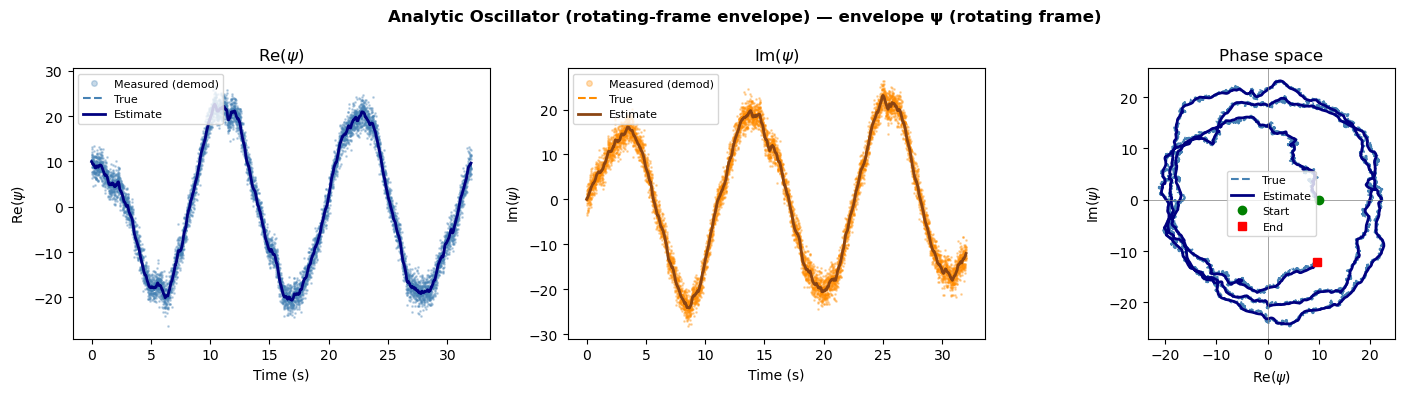

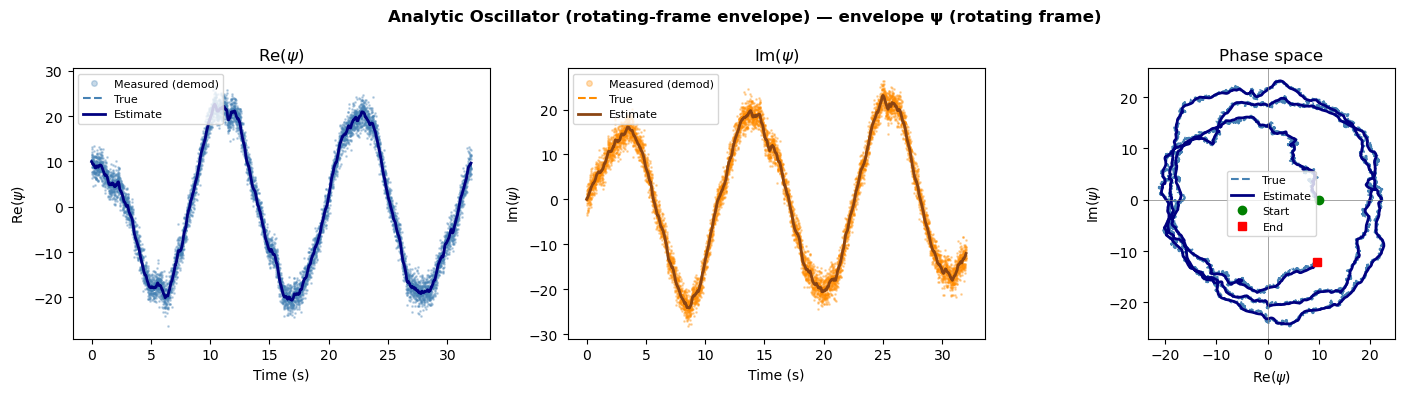

In [6]:
from kalman.apps.oscillators import AnalyticOscillatorModel

w0 = np.pi / 3    # natural frequency
fs = 256
T  = 32

# Case A: wc = w0  ->  dw = 0  ->  locked carrier (lock-in mode)
model_A = AnalyticOscillatorModel("f0", sample_rate=fs, w0=w0, wc=w0,
                                  Q=10000, measurement_uncertainty=2,
                                  process_uncertainty=0.01, random_seed=42)
model_A.initial_state([10, 0])
sample_A = model_A.sample(T)
record_A = model_A.filter(sample_A, smooth=True, reset=True,
                          preprocess=True, postprocess=False)

# Case B: wc != w0  ->  dw != 0  ->  detuned carrier (precessing)
wc_B = np.pi / 7
model_B = AnalyticOscillatorModel("f0", sample_rate=fs, w0=w0, wc=wc_B,
                                  Q=10000, measurement_uncertainty=2,
                                  process_uncertainty=0.01, random_seed=42)
model_B.initial_state([10, 0])
sample_B = model_B.sample(T)
record_B = model_B.filter(sample_B, smooth=True, reset=True,
                          preprocess=True, postprocess=False)

# Signature figure (model.plot): envelope psi -- Re/Im vs time + phase portrait,
# measurements demodulated into the rotating frame. One figure per detuning case.
model_A.plot(record_A, sample=sample_A, interactive=True)   # dw = 0       (lock-in)
model_B.plot(record_B, sample=sample_B)   # dw = w0 - wc (detuned, precessing)